### 1. Cross Validation Pipeline.

In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

complete = load_iris(as_frame=True)
df = complete.frame

print(df.isnull().sum())

X = df.drop(columns=["target"])
y = complete["target"]

num_cols = X.columns

preprocessor = ColumnTransformer([
    ("num_cols", Pipeline([
    ("scalar", StandardScaler())
    ]), num_cols)
])

pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=950)),
])

print(f"\nShape: {X.shape}")
print(f"\nFlower Types\n{y.value_counts()}")

sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
target               0
dtype: int64

Shape: (150, 4)

Flower Types
target
0    50
1    50
2    50
Name: count, dtype: int64


### 2. Accuracy Of Folds

4-fold accuracy scores: [0.974 0.947 0.946 0.973]
Mean: 0.960  Std: 0.013


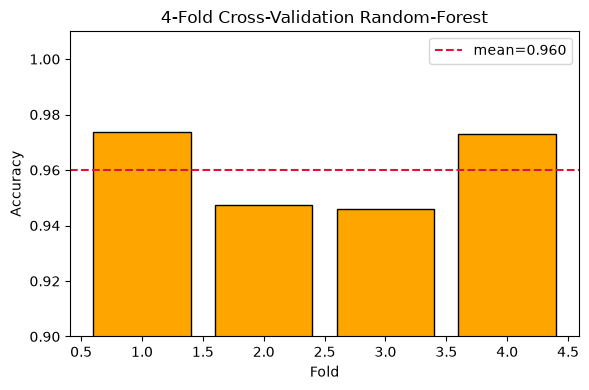

In [91]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import cross_val_score

cv_acc = cross_val_score(pipe, X, y, cv = 4, scoring="accuracy")
print("4-fold accuracy scores:", np.round(cv_acc, 3))
print(f"Mean: {cv_acc.mean():.3f}  Std: {cv_acc.std():.3f}")

plt.figure(figsize=(6, 4))
plt.bar(range(1, 5), cv_acc, color="orange", edgecolor="black")
plt.axhline(cv_acc.mean(), color="crimson", ls="--", label=f"mean={cv_acc.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("4-Fold Cross-Validation Random-Forest")
plt.ylim(0.9, 1.01)
plt.legend()
plt.tight_layout()
plt.show()

### 3. Saving The Model

In [ ]:
import numpy as np
from joblib import load, dump
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

pipe.fit(x_train, y_train)
dump(pipe, "iris.joblib_cross_val")
loaded_model = load("iris.joblib")

original_pred = pipe.predict(x_test)
loaded_pred = loaded_model.predict(x_test)

print(f"Same predictions: {np.allclose(original_pred, loaded_pred)}")

Same predictions: True
